In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from tensorflow import keras
import tensorflow as tf
from pathlib import Path
from PIL import Image
from keras.models import Sequential
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import  Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocessing 
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet50_preprocessing
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenetv2_preprocessing 
from keras import callbacks

In [2]:
train_dataset, validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/training",
    image_size=(224, 224),
    seed = 42,
    validation_split = 0.2,
    subset = "both",
    batch_size=32,
    label_mode="binary"
)

test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../data/testing",
    image_size=(224, 224),
    shuffle=False,
    batch_size=32,
    label_mode="binary"
)

Found 2392 files belonging to 2 classes.
Using 1914 files for training.
Using 478 files for validation.
Found 597 files belonging to 2 classes.


In [3]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(Flatten())
model.add(Dense(10, activation='relu'))
model.add(Dense(10, activation='relu'))
model.add(Dense(1, activation="sigmoid"))

model.compile(optimizer='adam',
              loss='binary_crossentropy', 
              metrics=[
                      tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                      tf.keras.metrics.Precision(name="precision"),
                      tf.keras.metrics.Recall(name="recall"),
                      tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
                      tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
                      tf.keras.metrics.AUC(curve="PR", name="pr_auc")
                  ])

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
results = model.evaluate(test_dataset, return_dict=True)
print(results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 31s 428ms/step - accuracy: 0.4948 - f1: 0.1685 - loss: 95.8834 - pr_auc: 0.5059 - precision: 0.5326 - recall: 0.1001 - roc_auc: 0.4848 - val_accuracy: 0.4749 - val_f1: 0.0000e+00 - val_loss: 0.6934 - val_pr_auc: 0.5251 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5000
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 315ms/step - accuracy: 0.4885 - f1: 0.0000e+00 - loss: 0.6933 - pr_auc: 0.5069 - precision: 0.0000e+00 - recall: 0.0000e+00 - roc_auc: 0.4911 - val_accuracy: 0.4749 - val_f1: 0.0000e+00 - val_loss: 0.6933 - val_pr_auc: 0.5251 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5000
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 21s 355ms/step - accuracy: 0.4885 - f1: 0.1359 - loss: 0.6932 - pr_auc: 0.5115 - precision: 0.5000 - recall: 0.0787 - roc_auc: 0.5000 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 0.6931 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 4/4

In [3]:
model = Sequential()
model.add(Input(shape=(224, 224, 3)))

model.add(Conv2D(16, kernel_size=3, 
                 activation='relu', 
                 padding='same'))
model.add(BatchNormalization())
model.add(MaxPool2D(2))
model.add(Conv2D(32, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Conv2D(64, kernel_size=3, activation='relu',padding='same'))
model.add(MaxPool2D(2))
model.add(Flatten())
model.add(Dense(1, activation="sigmoid"))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
        tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc")
    ]
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)
custom_model_results = model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 182s 3s/step - accuracy: 0.7074 - f1: 0.7180 - loss: 0.7037 - pr_auc: 0.7222 - precision: 0.7080 - recall: 0.7283 - roc_auc: 0.7592 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 4.9616 - val_pr_auc: 0.5251 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.5000
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 210s 3s/step - accuracy: 0.9164 - f1: 0.9185 - loss: 0.2042 - pr_auc: 0.9786 - precision: 0.9166 - recall: 0.9203 - roc_auc: 0.9764 - val_accuracy: 0.5251 - val_f1: 0.6886 - val_loss: 3.6045 - val_pr_auc: 0.5878 - val_precision: 0.5251 - val_recall: 1.0000 - val_roc_auc: 0.6123
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 193s 3s/step - accuracy: 0.9801 - f1: 0.9807 - loss: 0.0655 - pr_auc: 0.9982 - precision: 0.9757 - recall: 0.9857 - roc_auc: 0.9980 - val_accuracy: 0.6213 - val_f1: 0.7350 - val_loss: 1.6296 - val_pr_auc: 0.8223 - val_precision: 0.5810 - val_recall: 1.0000 - val_roc_auc: 0.8804
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 183s 3s/step - 

In [ ]:
model.save("../models/custom_model.keras")
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        50,177 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,413 (864.90 KB)

 Trainable params: 73,793 (288.25 KB)

 Non-trainable params: 32 (128.00 B)

 Optimizer params: 147,588 (576.52 KB)

73825

In [7]:
print(train_dataset.class_names)

['flip', 'notflip']


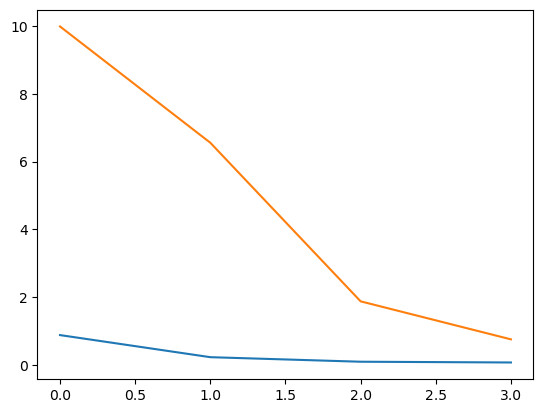

In [8]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.show()

In [7]:
resnet50_base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Keep its pretrained weights fixed
resnet50_base_model.trainable = False

resnet50_model = Sequential()
resnet50_model.add(Input(shape=(224, 224, 3)))
resnet50_model.add(tf.keras.layers.Lambda(resnet50_preprocessing))
resnet50_model.add(resnet50_base_model)
resnet50_model.add(GlobalAveragePooling2D())
resnet50_model.add(Dense(1, activation="sigmoid"))

resnet50_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

resnet50_model_history = resnet50_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 830s 13s/step - accuracy: 0.8255 - f1: 0.8317 - loss: 0.4105 - pr_auc: 0.9132 - precision: 0.8209 - recall: 0.8427 - roc_auc: 0.9124 - val_accuracy: 0.9205 - val_f1: 0.9266 - val_loss: 0.2822 - val_pr_auc: 0.9817 - val_precision: 0.8989 - val_recall: 0.9562 - val_roc_auc: 0.9816
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 492s 8s/step - accuracy: 0.9352 - f1: 0.9385 - loss: 0.2253 - pr_auc: 0.9855 - precision: 0.9122 - recall: 0.9663 - roc_auc: 0.9855 - val_accuracy: 0.9310 - val_f1: 0.9379 - val_loss: 0.2102 - val_pr_auc: 0.9928 - val_precision: 0.8893 - val_recall: 0.9920 - val_roc_auc: 0.9927
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 552s 9s/step - accuracy: 0.9498 - f1: 0.9523 - loss: 0.1707 - pr_auc: 0.9924 - precision: 0.9274 - recall: 0.9785 - roc_auc: 0.9923 - val_accuracy: 0.9686 - val_f1: 0.9708 - val_loss: 0.1564 - val_pr_auc: 0.9963 - val_precision: 0.9504 - val_recall: 0.9920 - val_roc_auc: 0.9962
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 534s 9s/step -

In [8]:
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
print(resnet50_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 120s 6s/step - accuracy: 0.9715 - f1: 0.9729 - loss: 0.1300 - pr_auc: 0.9973 - precision: 0.9531 - recall: 0.9935 - roc_auc: 0.9973        
{'accuracy': 0.9715242981910706, 'f1': 0.9728866815567017, 'loss': 0.12999607622623444, 'pr_auc': 0.9973423480987549, 'precision': 0.953125, 'recall': 0.9934853315353394, 'roc_auc': 0.9972649812698364}


In [ ]:
resnet50_model.save("../models/resnet50_model.keras")

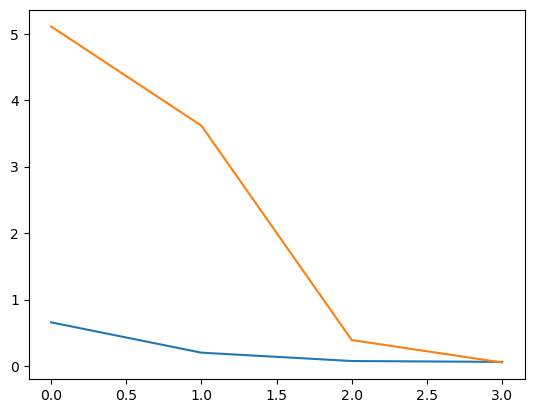

In [ ]:
plt.plot(resnet50_model_history.history['loss'])
plt.plot(resnet50_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base_model.trainable = False

vgg16_model = Sequential()
vgg16_model.add(Input(shape=(224, 224, 3)))
vgg16_model.add(tf.keras.layers.Lambda(vgg16_preprocessing))
vgg16_model.add(vgg16_base_model)
vgg16_model.add(GlobalAveragePooling2D())
vgg16_model.add(Dense(1, activation="sigmoid"))

vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_model_history = vgg16_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
print(vgg16_results)

Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1217s 20s/step - accuracy: 0.6014 - f1: 0.6472 - loss: 0.6782 - pr_auc: 0.6255 - precision: 0.5912 - recall: 0.7150 - roc_auc: 0.6387 - val_accuracy: 0.6548 - val_f1: 0.6421 - val_loss: 0.6636 - val_pr_auc: 0.7410 - val_precision: 0.7048 - val_recall: 0.5896 - val_roc_auc: 0.7334
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1111s 19s/step - accuracy: 0.6703 - f1: 0.6865 - loss: 0.6438 - pr_auc: 0.7745 - precision: 0.6683 - recall: 0.7058 - roc_auc: 0.7653 - val_accuracy: 0.6297 - val_f1: 0.6366 - val_loss: 0.6370 - val_pr_auc: 0.8153 - val_precision: 0.6568 - val_recall: 0.6175 - val_roc_auc: 0.7731
Epoch 3/4
29/60 ━━━━━━━━━━━━━━━━━━━━ 13:22 26s/step - accuracy: 0.6570 - f1: 0.6691 - loss: 0.6269 - pr_auc: 0.8210 - precision: 0.6480 - recall: 0.6971 - roc_auc: 0.7931

In [ ]:
vgg16_model.save("../models/vgg16_model.keras")

File size: 56.22 MB


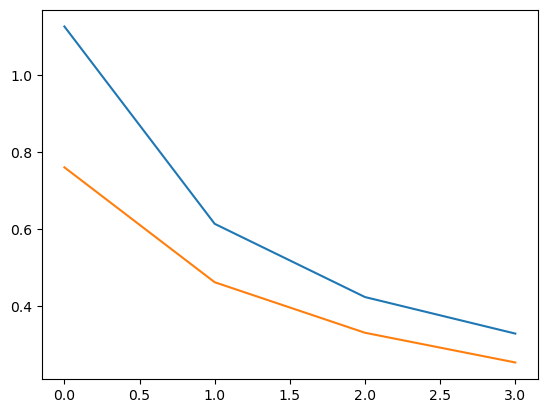

In [ ]:
plt.plot(vgg16_model_history.history['loss'])
plt.plot(vgg16_model_history.history['val_loss'])

plt.show()

In [ ]:
vgg16_base_model =  VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

augmentation_model = Sequential([
    #tf.keras.layers.RandomRotation(0.02),
    #tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

vgg16_base_model.trainable = False

vgg16_aug_model = Sequential()
vgg16_aug_model.add(Input(shape=(224, 224, 3)))
vgg16_aug_model.add(augmentation_model)
vgg16_aug_model.add(tf.keras.layers.Lambda(vgg16_preprocessing))
vgg16_aug_model.add(vgg16_base_model)
vgg16_aug_model.add(GlobalAveragePooling2D())
vgg16_aug_model.add(Dense(1, activation="sigmoid"))

vgg16_aug_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
vgg16_aug_model_history = vgg16_aug_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

vgg16_aug_model_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
print(vgg16_aug_model_results)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 1268s 21s/step - accuracy: 0.5538 - f1: 0.5810 - loss: 0.6906 - pr_auc: 0.5668 - precision: 0.5590 - recall: 0.6047 - roc_auc: 0.5634 - val_accuracy: 0.6569 - val_f1: 0.6952 - val_loss: 0.6676 - val_pr_auc: 0.7134 - val_precision: 0.6516 - val_recall: 0.7450 - val_roc_auc: 0.7115
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 892s 15s/step - accuracy: 0.6562 - f1: 0.6959 - loss: 0.6516 - pr_auc: 0.7735 - precision: 0.6354 - recall: 0.7692 - roc_auc: 0.7486 - val_accuracy: 0.6569 - val_f1: 0.6894 - val_loss: 0.6398 - val_pr_auc: 0.7961 - val_precision: 0.6570 - val_recall: 0.7251 - val_roc_auc: 0.7666
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 970s 16s/step - accuracy: 0.6724 - f1: 0.7041 - loss: 0.6244 - pr_auc: 0.7989 - precision: 0.6544 - recall: 0.7620 - roc_auc: 0.7773 - val_accuracy: 0.6904 - val_f1: 0.7448 - val_loss: 0.6175 - val_pr_auc: 0.8256 - val_precision: 0.6565 - val_recall: 0.8606 - val_roc_auc: 0.7918
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 966s 16s/s

In [ ]:
vgg16_aug_model.save("../models/vgg16_aug_model.keras")

In [ ]:
efficientnetb0_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnetb0_base_model.trainable = False

efficientnetb0_model = Sequential()
efficientnetb0_model.add(Input(shape=(224, 224, 3)))
efficientnetb0_model.add(efficientnetb0_base_model)
efficientnetb0_model.add(GlobalAveragePooling2D())
efficientnetb0_model.add(Dense(1, activation="sigmoid"))

efficientnetb0_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
efficientnetb0_model_history = efficientnetb0_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
print(efficientnetb0_results)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 438s 7s/step - accuracy: 0.6661 - f1: 0.6918 - loss: 0.6136 - pr_auc: 0.7022 - precision: 0.6554 - recall: 0.7324 - roc_auc: 0.7316 - val_accuracy: 0.8347 - val_f1: 0.8597 - val_loss: 0.5104 - val_pr_auc: 0.8735 - val_precision: 0.7756 - val_recall: 0.9641 - val_roc_auc: 0.9047
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 352s 6s/step - accuracy: 0.8464 - f1: 0.8599 - loss: 0.4613 - pr_auc: 0.9126 - precision: 0.8061 - recall: 0.9213 - roc_auc: 0.9232 - val_accuracy: 0.8975 - val_f1: 0.9070 - val_loss: 0.4028 - val_pr_auc: 0.9654 - val_precision: 0.8659 - val_recall: 0.9522 - val_roc_auc: 0.9676
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 309s 5s/step - accuracy: 0.8887 - f1: 0.8972 - loss: 0.3808 - pr_auc: 0.9548 - precision: 0.8507 - recall: 0.9489 - roc_auc: 0.9570 - val_accuracy: 0.9079 - val_f1: 0.9179 - val_loss: 0.3394 - val_pr_auc: 0.9801 - val_precision: 0.8632 - val_recall: 0.9801 - val_roc_auc: 0.9791
E

In [ ]:
efficientnetb0_model.save("../models/efficientnetb0_model.keras")

File size: 16.27 MB


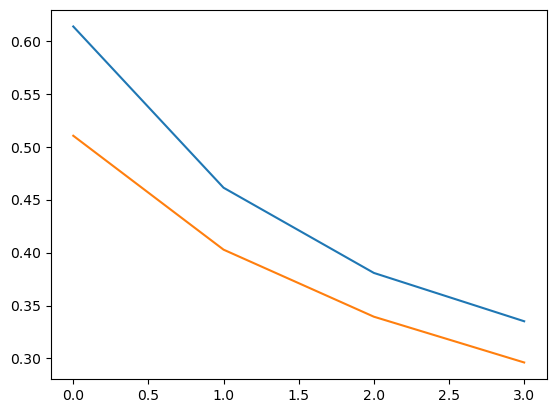

In [ ]:
plt.plot(efficientnetb0_model_history.history['loss'])
plt.plot(efficientnetb0_model_history.history['val_loss'])

plt.show()

In [3]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = False

mobilenetv2_model = Sequential()
mobilenetv2_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_model.add(tf.keras.layers.Lambda(mobilenetv2_preprocessing))
mobilenetv2_model.add(mobilenetv2_base_model)
mobilenetv2_model.add(GlobalAveragePooling2D())
mobilenetv2_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)
mobilenetv2_model_history = mobilenetv2_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=4
)

mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_results)


Epoch 1/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 317s 5s/step - accuracy: 0.7090 - f1: 0.7249 - loss: 0.5561 - pr_auc: 0.7867 - precision: 0.7017 - recall: 0.7497 - roc_auc: 0.7895 - val_accuracy: 0.8577 - val_f1: 0.8629 - val_loss: 0.4291 - val_pr_auc: 0.9289 - val_precision: 0.8735 - val_recall: 0.8526 - val_roc_auc: 0.9291
Epoch 2/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 182s 3s/step - accuracy: 0.8605 - f1: 0.8679 - loss: 0.3690 - pr_auc: 0.9463 - precision: 0.8417 - recall: 0.8958 - roc_auc: 0.9469 - val_accuracy: 0.8912 - val_f1: 0.9033 - val_loss: 0.3270 - val_pr_auc: 0.9695 - val_precision: 0.8467 - val_recall: 0.9681 - val_roc_auc: 0.9672
Epoch 3/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 0.8997 - f1: 0.9053 - loss: 0.2945 - pr_auc: 0.9717 - precision: 0.8751 - recall: 0.9377 - roc_auc: 0.9721 - val_accuracy: 0.9142 - val_f1: 0.9219 - val_loss: 0.2735 - val_pr_auc: 0.9794 - val_precision: 0.8832 - val_recall: 0.9641 - val_roc_auc: 0.9772
Epoch 4/4
60/60 ━━━━━━━━━━━━━━━━━━━━ 175s 3s/step -

In [4]:
mobilenetv2_model.save("../models/mobilenetv2_model.keras")

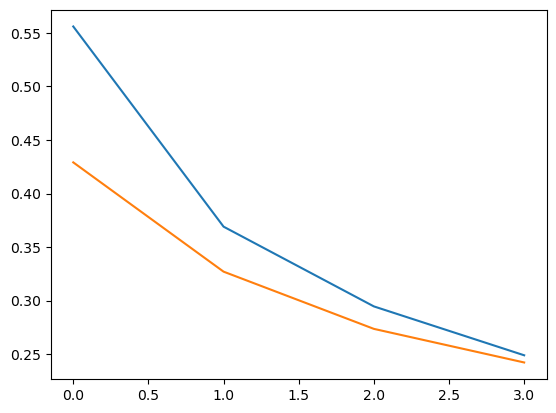

In [5]:
plt.plot(mobilenetv2_model_history.history['loss'])
plt.plot(mobilenetv2_model_history.history['val_loss'])

plt.show()

In [12]:
mobilenetv2_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

mobilenetv2_base_model.trainable = True


for layer in mobilenetv2_base_model.layers[:-20]:
    layer.trainable = False


mobilenetv2_tuned_model = Sequential()
mobilenetv2_tuned_model.add(Input(shape=(224, 224, 3)))
mobilenetv2_tuned_model.add(tf.keras.layers.Lambda(mobilenetv2_preprocessing))
mobilenetv2_tuned_model.add(mobilenetv2_base_model)
mobilenetv2_tuned_model.add(GlobalAveragePooling2D())
mobilenetv2_tuned_model.add(Dense(1, activation="sigmoid"))

mobilenetv2_tuned_model.compile(
    optimizer= tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.F1Score(threshold=0.5, name="f1"),
            tf.keras.metrics.AUC(curve="ROC", name="roc_auc"),
            tf.keras.metrics.AUC(curve="PR", name="pr_auc")
        ]
)

earlystopping = callbacks.EarlyStopping(monitor="val_loss",
                                        mode="min",
                                        patience=3,
                                        restore_best_weights=True)


mobilenetv2_tuned_model_history = mobilenetv2_tuned_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks = [earlystopping]

)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 244s 4s/step - accuracy: 0.6682 - f1: 0.6053 - loss: 0.6038 - pr_auc: 0.7705 - precision: 0.7730 - recall: 0.4974 - roc_auc: 0.7609 - val_accuracy: 0.6318 - val_f1: 0.5000 - val_loss: 0.6055 - val_pr_auc: 0.8217 - val_precision: 0.8713 - val_recall: 0.3506 - val_roc_auc: 0.8253
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 212s 4s/step - accuracy: 0.9013 - f1: 0.9033 - loss: 0.3766 - pr_auc: 0.9609 - precision: 0.9047 - recall: 0.9019 - roc_auc: 0.9625 - val_accuracy: 0.7971 - val_f1: 0.7780 - val_loss: 0.4814 - val_pr_auc: 0.9179 - val_precision: 0.9140 - val_recall: 0.6773 - val_roc_auc: 0.9185
Epoch 3/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.9472 - f1: 0.9493 - loss: 0.2680 - pr_auc: 0.9874 - precision: 0.9338 - recall: 0.9653 - roc_auc: 0.9870 - val_accuracy: 0.8745 - val_f1: 0.8729 - val_loss: 0.3935 - val_pr_auc: 0.9555 - val_precision: 0.9321 - val_recall: 0.8207 - val_roc_auc: 0.9546
Epoch 4/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 204s 3s/step - 

In [13]:
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
print(mobilenetv2_tuned_results)

19/19 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.9464 - f1: 0.9477 - loss: 0.2693 - pr_auc: 0.9887 - precision: 0.9508 - recall: 0.9446 - roc_auc: 0.9885     
{'accuracy': 0.9463986754417419, 'f1': 0.9477123022079468, 'loss': 0.269307404756546, 'pr_auc': 0.9887137413024902, 'precision': 0.9508196711540222, 'recall': 0.9446253776550293, 'roc_auc': 0.9885039329528809}


In [7]:
mobilenetv2_tuned_model.save("../models/mobilenetv2_tuned_model.keras")

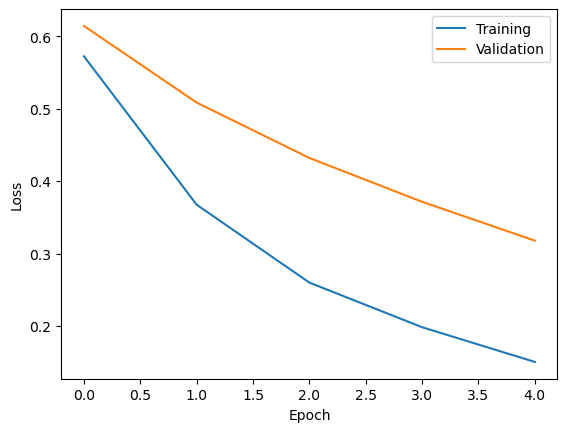

In [8]:
plt.plot(mobilenetv2_tuned_model_history.history['loss'], label="Training")
plt.plot(mobilenetv2_tuned_model_history.history['val_loss'], label ="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.show()

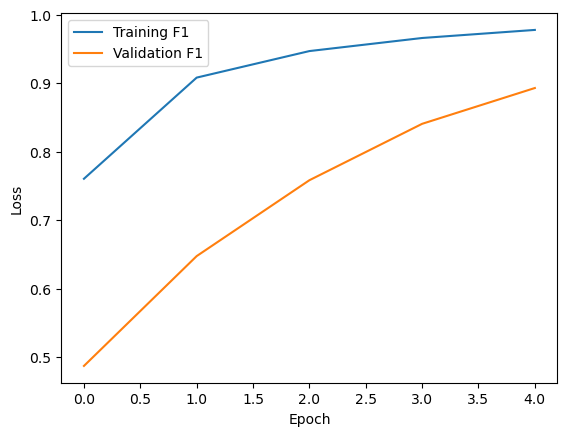

In [9]:
plt.plot(mobilenetv2_tuned_model_history.history["f1"], label="Training F1")
plt.plot(mobilenetv2_tuned_model_history.history["val_f1"], label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [3]:
baseline_model = load_model("../models/custom_model.keras")
custom_model_results = baseline_model.evaluate(test_dataset, return_dict=True)
print(custom_model_results)
path = Path("../models/custom_model.keras")
custom_model_file_size = round(path.stat().st_size / (1024**2),2)
custom_model_params = baseline_model.count_params()

resnet50_model = load_model("../models/resnet50_model.keras", custom_objects={"preprocess_input": resnet50_preprocessing})
resnet50_results = resnet50_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/resnet50_model.keras")
resnet50_file_size = round(path.stat().st_size / (1024**2),2)
resnet50_params = resnet50_model.count_params()

vgg16_model = load_model("../models/vgg16_model.keras", custom_objects={"preprocess_input": vgg16_preprocessing})
vgg16_results = vgg16_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/vgg16_model.keras")
vgg16_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_params = vgg16_model.count_params()

vgg16_aug_model = load_model("../models/vgg16_aug_model.keras", custom_objects={"preprocess_input": vgg16_preprocessing})
vgg16_aug_results = vgg16_aug_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/vgg16_aug_model.keras")
vgg16_aug_file_size = round(path.stat().st_size / (1024**2),2)
vgg16_aug_params = vgg16_aug_model.count_params()

efficientnetb0_model = load_model("../models/efficientnetb0_model.keras")
efficientnetb0_results = efficientnetb0_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/efficientnetb0_model.keras")
efficientnetb0_file_size = round(path.stat().st_size / (1024**2),2)
efficientnetb0_params = efficientnetb0_model.count_params()

mobilenetv2_model = load_model("../models/mobilenetv2_model.keras", custom_objects={"preprocess_input": mobilenetv2_preprocessing})
mobilenetv2_results = mobilenetv2_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/mobilenetv2_model.keras")
mobilenetv2_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_params = mobilenetv2_model.count_params()

mobilenetv2_tuned_model = load_model("../models/mobilenetv2_tuned_model.keras", custom_objects={"preprocess_input": mobilenetv2_preprocessing})
mobilenetv2_tuned_results = mobilenetv2_tuned_model.evaluate(test_dataset, return_dict=True)
path = Path("../models/mobilenetv2_tuned_model.keras")
mobilenetv2_tuned_file_size = round(path.stat().st_size / (1024**2),2)
mobilenetv2_tuned_params = mobilenetv2_tuned_model.count_params()



19/19 ━━━━━━━━━━━━━━━━━━━━ 20s 687ms/step - accuracy: 0.8777 - f1: 0.8937 - loss: 0.3277 - pr_auc: 0.9902 - precision: 0.8079 - recall: 1.0000 - roc_auc: 0.9948         
{'accuracy': 0.8777219653129578, 'f1': 0.8937408924102783, 'loss': 0.32771024107933044, 'pr_auc': 0.9902495741844177, 'precision': 0.807894766330719, 'recall': 1.0, 'roc_auc': 0.9947826862335205}

19/19 ━━━━━━━━━━━━━━━━━━━━ 140s 6s/step - accuracy: 0.4858 - f1: 0.0000e+00 - loss: 6.9083 - pr_auc: 0.5142 - precision: 0.0000e+00 - recall: 0.0000e+00 - roc_auc: 0.5000
19/19 ━━━━━━━━━━━━━━━━━━━━ 248s 12s/step - accuracy: 0.8660 - f1: 0.8662 - loss: 0.3194 - pr_auc: 0.9410 - precision: 0.8900 - recall: 0.8436 - roc_auc: 0.9429      
19/19 ━━━━━━━━━━━━━━━━━━━━ 191s 10s/step - accuracy: 0.6767 - f1: 0.6497 - loss: 1.2232 - pr_auc: 0.7630 - precision: 0.7336 - recall: 0.5831 - roc_auc: 0.7751      
19/19 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.9162 - f1: 0.9216 - loss: 0.3060 - pr_auc: 0.9797 - precision: 0.8882 - recal

In [14]:
comparsion_table = pd.DataFrame({
    "Model": ["Custom_Model", "ResNet50", "VGG16", "VGG16_Aug", "EfficientnetB0", "MobilenetV2", "MobilenetV2_tuned"],
    "Accuracy": [custom_model_results["accuracy"], resnet50_results["accuracy"], vgg16_results["accuracy"], vgg16_aug_results["accuracy"], efficientnetb0_results["accuracy"], mobilenetv2_results["accuracy"], mobilenetv2_tuned_results["accuracy"]],
    "F1": [custom_model_results["f1"], resnet50_results["f1"], vgg16_results["f1"], vgg16_aug_results["f1"], efficientnetb0_results["f1"], mobilenetv2_results["f1"], mobilenetv2_tuned_results["f1"]],
    "Recall": [custom_model_results["recall"], resnet50_results["recall"], vgg16_results["recall"], vgg16_aug_results["recall"], efficientnetb0_results["recall"], mobilenetv2_results["recall"], mobilenetv2_tuned_results["recall"]],
    "Precision": [custom_model_results["precision"], resnet50_results["precision"], vgg16_results["precision"], vgg16_aug_results["precision"], efficientnetb0_results["precision"], mobilenetv2_results["precision"], mobilenetv2_tuned_results["precision"]],
    "ROC_AUC": [custom_model_results["roc_auc"], resnet50_results["roc_auc"], vgg16_results["roc_auc"], vgg16_aug_results["roc_auc"], efficientnetb0_results["roc_auc"], mobilenetv2_results["roc_auc"], mobilenetv2_tuned_results["roc_auc"]],
    "PR_AUC": [custom_model_results["pr_auc"], resnet50_results["pr_auc"], vgg16_results["pr_auc"], vgg16_aug_results["pr_auc"], efficientnetb0_results["pr_auc"], mobilenetv2_results["pr_auc"], mobilenetv2_tuned_results["pr_auc"]],
    "File_Size_MB": [custom_model_file_size, resnet50_file_size, vgg16_file_size, vgg16_aug_file_size, efficientnetb0_file_size, mobilenetv2_file_size, mobilenetv2_tuned_file_size],
    "Parameters": [custom_model_params, resnet50_params, vgg16_params, vgg16_aug_params, efficientnetb0_params, mobilenetv2_params, mobilenetv2_tuned_params]
})

In [15]:
comparsion_table.to_csv("../data/comparsion.csv")

In [16]:
comparsion_table

,Model,Accuracy,F1,Recall,Precision,ROC_AUC,PR_AUC,File_Size_MB,Parameters
0,Custom_Model,0.877722,0.893741,1.000000,0.807895,0.994783,0.990250,0.89,73825
1,ResNet50,0.971524,0.972887,0.993485,0.953125,0.997265,0.997342,90.63,23589761
2,VGG16,0.865997,0.866221,0.843648,0.890034,0.942912,0.940999,56.22,14715201
3,VGG16_Aug,0.676717,0.649728,0.583062,0.733607,0.775076,0.763047,56.23,14715201
4,EfficientnetB0,0.916248,0.921630,0.957655,0.888218,0.977991,0.979725,16.27,4050852
5,MobilenetV2,0.926298,0.927631,0.918567,0.936877,0.983124,0.984609,9.19,2259265
6,MobilenetV2_tuned,0.946399,0.947712,0.944625,0.950820,0.988504,0.988714,18.40,2259265


In [ ]:
import os

os.environ["KERAS_BACKEND"] = "tensorflow"

import numpy as np
import tensorflow as tf
import keras

# Display
from IPython.display import Image, display
import matplotlib as mpl
import matplotlib.pyplot as plt


In [37]:
# Your trained model
model = mobilenetv2_tuned_model

img_size = (224, 224)

# Use the same preprocessing already included in your model.
# Do not preprocess the image again outside the model.

# Last convolutional layer in MobileNetV2
last_conv_layer_name = "Conv_1"

# Path to one of your test images
import random
import glob

img_path = random.choice(glob.glob("../data/testing/flip/*.jpg"))


In [40]:
def get_img_array(img_path, size=(224, 224)):
    # Load and resize the image to 224 × 224
    img = keras.utils.load_img(img_path, target_size=size)

    # Convert to a float32 array: (224, 224, 3)
    array = keras.utils.img_to_array(img)

    # Add the batch dimension: (1, 224, 224, 3)
    array = np.expand_dims(array, axis=0)

    return array

In [41]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name="out_relu",
                         pred_index=None):

    # Find the MobileNetV2 base inside your Sequential model
    base_model = next(
        layer for layer in model.layers
        if isinstance(layer, keras.Model)
    )

    grad_model = keras.models.Model(
        base_model.inputs,
        [
            base_model.get_layer(last_conv_layer_name).output,
            base_model.output
        ]
    )

    x = tf.convert_to_tensor(img_array, dtype=tf.float32)
    base_index = model.layers.index(base_model)

    # Apply preprocessing layers before the base model
    for layer in model.layers[:base_index]:
        x = layer(x, training=False)

    with tf.GradientTape() as tape:
        tape.watch(x)

        conv_output, x = grad_model(x, training=False)

        # Apply pooling and classification layers
        for layer in model.layers[base_index + 1:]:
            x = layer(x, training=False)

        # Select the predicted class unless one is specified
        if pred_index is None:
            pred_index = int(x[0, 0] >= 0.5)

        class_score = x[:, 0] if pred_index == 1 else 1 - x[:, 0]

    # Calculate feature-map importance
    grads = tape.gradient(class_score, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Combine feature maps into a heatmap
    heatmap = tf.reduce_sum(conv_output[0] * pooled_grads, axis=-1)

    # Normalize between 0 and 1
    heatmap = tf.maximum(heatmap, 0)
    heatmap = tf.math.divide_no_nan(heatmap, tf.reduce_max(heatmap))

    return heatmap.numpy()

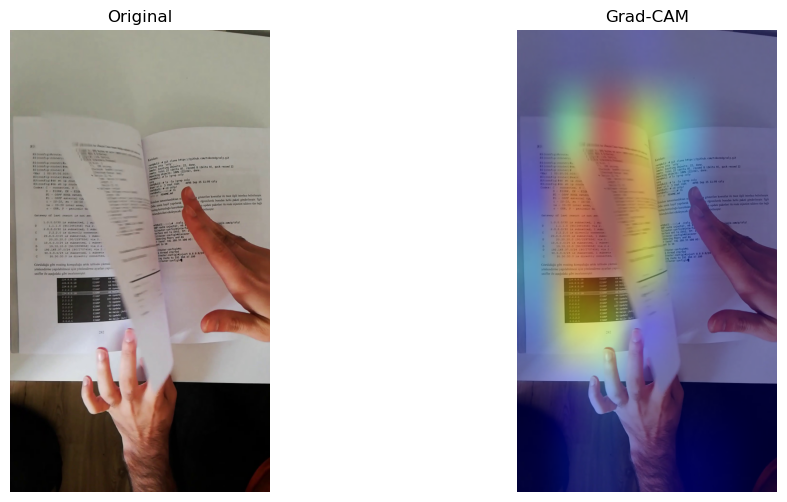

In [ ]:

def save_and_display_gradcam(img_path, heatmap,
                             cam_path="../reports/cam.jpg", alpha=0.4):
    # Load the original image
    original = keras.utils.load_img(img_path)
    img = keras.utils.img_to_array(original)

    # Convert the heatmap to RGB colours
    heatmap = np.uint8(255 * np.clip(heatmap, 0, 1))
    colored_heatmap = plt.get_cmap("jet")(heatmap)[..., :3]
    colored_heatmap = np.uint8(255 * colored_heatmap)

    # Resize the heatmap to match the original image
    colored_heatmap = keras.utils.array_to_img(
        colored_heatmap, scale=False
    )
    colored_heatmap = colored_heatmap.resize(
        (img.shape[1], img.shape[0])
    )
    colored_heatmap = keras.utils.img_to_array(colored_heatmap)

    # Blend the heatmap with the original image
    overlay = (1 - alpha) * img + alpha * colored_heatmap
    overlay = keras.utils.array_to_img(overlay, scale=False)

    # Save the overlay
    Path(cam_path).parent.mkdir(parents=True, exist_ok=True)
    overlay.save(cam_path)

    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img.astype("uint8"))
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay)
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.show()
save_and_display_gradcam(img_path, heatmap)